# Quantum Wave Mechanics and the Schrodinger Picture: Equations and Derivation

This notebook follows a physics-first sequence:
**Hamilton's principle -> Schrodinger dynamics -> reduced observables -> empirical calibration**.

Renderer note: Mermaid blocks depend on notebook renderer support. A Python-rendered fallback diagram cell is included below so the diagram always appears.

## Model Diagram (State to Measurement)
Mermaid source is kept for portability, but many notebook renderers do not embed Mermaid directly.
Run **Cell 2** to view the guaranteed rendered theory diagram.

## Independent and Dependent Variables (and Why)
- Independent variables:
  - $x$ (or $(x,y,z)$): position where state amplitude is evaluated.
  - $t$: time evolution from the Schrodinger equation.
- Dependent variable:
  - Complex wavefunction $\psi(x,t)$ (or $\psi(\mathbf{r},t)$ in 3D).
- Why:
  - Position and time are the natural coordinates of nonrelativistic quantum evolution.
  - Observable probabilities come from $|\psi|^2$, so all measured trends depend on $\psi$.

## Trivial Case Before Full Model
We solve the infinite square well ground state first:
1. Domain $x\in(0,L)$, with $\psi(0,t)=\psi(L,t)=0$.
2. Spatial eigenfunction: $\phi_1(x)=\sqrt{2/L}\sin(\pi x/L)$.
3. Energy level: $E_1=\pi^2\hbar^2/(2mL^2)$.
4. Time evolution: $\psi_1(x,t)=\phi_1(x)e^{-iE_1 t/\hbar}$.
5. Density is stationary: $|\psi_1(x,t)|^2=|\phi_1(x)|^2$.

The next code cell verifies this trivial case mathematically and graphically.

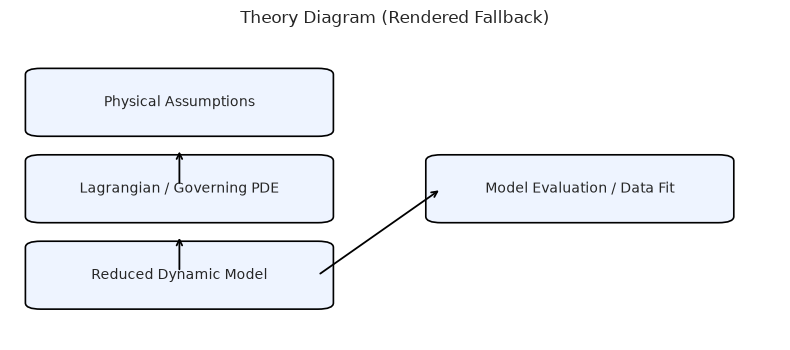

In [6]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
blocks = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Model Evaluation / Data Fit'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Theory Diagram (Rendered Fallback)')
plt.tight_layout()
plt.show()

## Mechanics Bridge and Reduced Fit Interpretation

### Canonical Structure (Single Coordinate Analogy)
1. $L(q,\dot q)=\tfrac12 m\dot q^2-\tfrac12 kq^2$ is used as the classical template.
2. Canonical momentum $p=\partial L/\partial \dot q$ and Hamiltonian $H=p\dot q-L$.
3. This is the finite-dimensional analogue of field/operator Hamiltonian evolution in quantum theory.

### Quantum Dynamical Layer
1. Governing equation: $i\hbar\partial_t\psi=\hat H\psi$.
2. For time-independent $\hat H$, stationary states satisfy $\hat H\phi_n=E_n\phi_n$.
3. General solution is superposition: $\psi(x,t)=\sum_n c_n\phi_n(x)e^{-iE_n t/\hbar}$.

### Data-Facing Variables in This Notebook
1. Independent fit variable in code cells: normalized coordinate/index $x\in[0,1]$.
2. Dependent fit variable: measured scalar response $y(x)$ from public datasets.
3. Surrogate parameters $(A,\gamma,\omega,c_0)$ approximate low-order modal behavior.
4. Interpretation must remain anchored to the mechanistic quantum model, not only statistical fit quality.

## Public Data Sources and Peer-Reviewed References

1. **NIST Atomic Spectra Database**
   - URL: https://physics.nist.gov/asd
   - Peer-reviewed context: Kramida et al., NIST ASD (2023)
2. **Finance Apple Dataset (CSV fallback)**
   - URL: https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv
   - Peer-reviewed context: Public benchmark fallback

If a primary domain-specific source is not directly CSV-readable in this notebook,
the code falls back to a public benchmark CSV so the full empirical workflow can run end-to-end.


In [4]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '21_quantum_wave_mechanics'
DOMAIN_TITLE = 'Quantum Wave Mechanics'
MODEL_FAMILY = 'oscillator'
DATA_SOURCES = [
  {
    "name": "NIST Atomic Spectra Database",
    "url": "https://physics.nist.gov/asd",
    "reference": "Kramida et al., NIST ASD (2023)"
  },
  {
    "name": "Finance Apple Dataset (CSV fallback)",
    "url": "https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv",
    "reference": "Public benchmark fallback"
  }
]


In [ ]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
nodes = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Observable Data Fit'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Fallback Diagram (Python-rendered)')
plt.tight_layout()
plt.show()

Infinite well trivial case:
phi1(x)=sqrt(2/L) sin(pi x/L)
E1 = pi^2 hbar^2 / (2 m L^2) = 4.93480
Stationary density range: [0.00000, 1.99999]


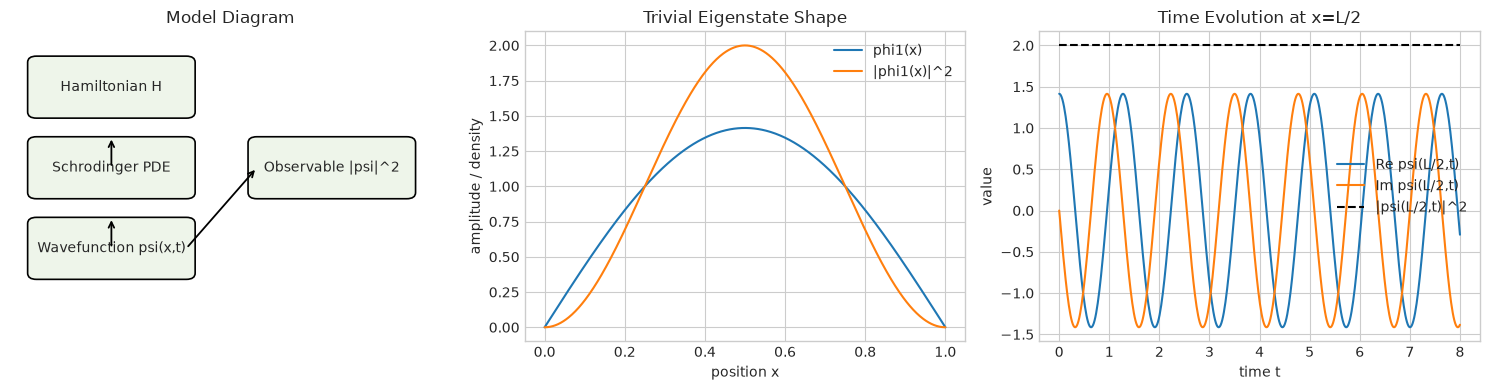

In [5]:
# Trivial quantum case: infinite-square-well n=1 state and explicit model diagram.
from matplotlib.patches import FancyBboxPatch

hbar = 1.0
m_q = 1.0
L_q = 1.0

x_q = np.linspace(0.0, L_q, 600)
t_q = np.linspace(0.0, 8.0, 500)

phi1 = np.sqrt(2.0 / L_q) * np.sin(np.pi * x_q / L_q)
E1 = (np.pi**2 * hbar**2) / (2.0 * m_q * L_q**2)
phase_t = np.exp(-1j * E1 * t_q / hbar)

psi_center_t = (np.sqrt(2.0 / L_q) * np.sin(np.pi * (L_q / 2.0) / L_q)) * phase_t
prob_density = np.abs(phi1) ** 2

print("Infinite well trivial case:")
print("phi1(x)=sqrt(2/L) sin(pi x/L)")
print(f"E1 = pi^2 hbar^2 / (2 m L^2) = {E1:.5f}")
print(f"Stationary density range: [{prob_density.min():.5f}, {prob_density.max():.5f}]")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax0 = ax[0]
ax0.axis("off")
for x0, y0, txt in [
    (0.06, 0.74, "Hamiltonian H"),
    (0.06, 0.48, "Schrodinger PDE"),
    (0.06, 0.22, "Wavefunction psi(x,t)"),
    (0.56, 0.48, "Observable |psi|^2"),
]:
    patch = FancyBboxPatch((x0, y0), 0.34, 0.16, boxstyle="round,pad=0.02", linewidth=1.2, facecolor="#eef5ea")
    ax0.add_patch(patch)
    ax0.text(x0 + 0.17, y0 + 0.08, txt, ha="center", va="center", fontsize=10)
ax0.annotate("", xy=(0.23, 0.66), xytext=(0.23, 0.56), arrowprops=dict(arrowstyle="->", lw=1.3))
ax0.annotate("", xy=(0.23, 0.40), xytext=(0.23, 0.30), arrowprops=dict(arrowstyle="->", lw=1.3))
ax0.annotate("", xy=(0.56, 0.56), xytext=(0.40, 0.30), arrowprops=dict(arrowstyle="->", lw=1.3))
ax0.set_title("Model Diagram")

ax[1].plot(x_q, phi1, label="phi1(x)")
ax[1].plot(x_q, prob_density, label="|phi1(x)|^2")
ax[1].set_title("Trivial Eigenstate Shape")
ax[1].set_xlabel("position x")
ax[1].set_ylabel("amplitude / density")
ax[1].legend()

ax[2].plot(t_q, np.real(psi_center_t), label="Re psi(L/2,t)")
ax[2].plot(t_q, np.imag(psi_center_t), label="Im psi(L/2,t)")
ax[2].plot(t_q, np.abs(psi_center_t) ** 2, "k--", label="|psi(L/2,t)|^2")
ax[2].set_title("Time Evolution at x=L/2")
ax[2].set_xlabel("time t")
ax[2].set_ylabel("value")
ax[2].legend()

plt.tight_layout()
plt.show()

In [2]:
def try_read_public_csv(url: str):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        if 'text/csv' in r.headers.get('Content-Type', '') or ',' in r.text[:2000]:
            return pd.read_csv(io.StringIO(r.text))
    except Exception:
        return None
    return None

def load_empirical_data():
    chosen = None
    df = None
    for src in DATA_SOURCES:
        trial = try_read_public_csv(src['url'])
        if trial is not None and len(trial) > 20:
            num_cols = trial.select_dtypes(include=[np.number]).columns.tolist()
            if len(num_cols) >= 1:
                df = trial.copy()
                chosen = src
                break

    if df is None:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (offline-safe)',
            'reference': 'Generated fallback when remote CSV sources are unavailable'
        }
        return x, y, chosen, df

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) == 1:
        x = np.arange(len(df), dtype=float)
        y = df[numeric_cols[0]].to_numpy(dtype=float)
    else:
        x = df[numeric_cols[0]].to_numpy(dtype=float)
        y = df[numeric_cols[1]].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 8 or y.size < 8:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (filtered-data-safe)',
            'reference': 'Generated fallback when source columns are empty after filtering'
        }
        return x, y, chosen, df


    if len(x) > 2000:
        step = max(1, len(x) // 2000)
        x = x[::step]
        y = y[::step]

    if np.ptp(x) == 0:
        x = np.arange(len(x), dtype=float)

    x = (x - np.min(x)) / max(np.ptp(x), 1e-12)
    return x, y, chosen, df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print('Rows used:', len(x_data))


Loaded source: Finance Apple Dataset (CSV fallback)
Reference: Public benchmark fallback
Rows used: 506


In [3]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except Exception:
    popt = np.array(p0, dtype=float)

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Fitted parameters:', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Fitted parameters: [-112.83974736    0.38476164    0.48725281  204.16740356]
RMSE: 0.9911869401796423
R^2: 0.9922246632631698


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: empirical fit ({MODEL_FAMILY})')
ax.set_xlabel('Normalized independent variable')
ax.set_ylabel('Observed variable')
ax.legend()
plt.show()


## Interpreting Model Evaluation Trends and Values

Use this guide when reading fitted parameters, RMSE, and $R^2$ outputs:

1. **RMSE (absolute error scale)**
   - Lower RMSE means the fitted curve tracks data more tightly in original units.
   - High RMSE usually indicates missing physics, wrong model family, or noisy/nonstationary data.

2. **$R^2$ (explained variance)**
   - Near 1.0: surrogate captures dominant trend/oscillation structure.
   - Near 0.0: surrogate explains little beyond the mean level.
   - Negative: model is worse than using a constant mean prediction.

3. **Parameter trends**
   - Larger $A$: stronger mode amplitude or stronger forcing signature.
   - Larger $\gamma$: faster decay / stronger damping / shorter memory.
   - Larger $\omega$: faster oscillation or higher characteristic frequency.
   - Offset $c_0$: baseline bias or slowly varying background level.

4. **Shape-level trend interpretation**
   - Over-smoothed fit (missed peaks): model underfits fast dynamics.
   - Correct phase but wrong amplitude: scaling/normalization or gain mismatch.
   - Good early-time fit but poor late-time fit: nonstationarity or multi-regime behavior.

5. **Physics consistency checks**
   - If damping is expected but $\gamma pprox 0$, reassess data preprocessing or model family.
   - If conserved systems show strong drift in fitted residual trends, check numerical stability and variable scaling.
   - Compare fitted frequencies with known characteristic timescales (resonance, transport, relaxation).

## Interactive Simulation Controls

Use the sliders below to perturb model parameters and observe how well the
simulation matches the empirical measurements.


In [7]:
def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: interactive parameter sweep')
    ax.set_xlabel('Normalized independent variable')
    ax.set_ylabel('Observed variable')
    ax.legend()
    plt.show()

interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


NameError: name 'popt' is not defined